# Run Chart (quality improvement)

**Family:** Healthcare & life sciences &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Intermediate

> *Healthcare & life sciences:* Clinical trials, survival, oncology, hospital quality and operations, epidemiology and patient-level records.

> ⚠️ Examples use simulated data. De-identify patient data before analysing it in notebooks: executed notebooks store their outputs.

## Design purpose

A time-ordered line of a process measure with its median, read with a few probability-based rules (shift, trend, number of runs). It separates real change from the ordinary month-to-month noise that tempts teams to react to every up and down, and it needs no control limits or distributional assumptions.

## When to use

- Judge whether a change (new protocol, staffing, audit) actually improved a process measure
- Track a quality indicator monthly or weekly when you have roughly 10 or more points
- Start quality-improvement work before you have enough data for a control chart

## Avoid when

- You have fewer than about 10 points (the rules have little power)
- You need to know whether a single point is unusual (use a control chart with limits)
- The measure is a mix of very different denominators month to month (use a p-chart)

## Alternatives

- Control chart (p-chart, u-chart, XmR) with 3-sigma limits
- Before/after box plots (loses the time order)

## Design tips

- Shift: 6 or more consecutive points on one side of the median; points exactly on the median neither break nor count
- Trend: 5 or more consecutive points all going up (or all down); repeated values are skipped
- Freeze the baseline median before the change and extend it, so the post-change points are judged against the old process
- Annotate when the change was made; the reader should see cause and effect on one axis
- Don't add a linear trend line; it imposes a model the rules don't need

## Example

Simulated monthly hand-hygiene compliance on a hospital ward over 30 months. A new alcohol-rub dispenser and feedback programme starts in month 16. The median is frozen from the 15 baseline months.

### Setup

In [1]:
import sys
from pathlib import Path
# This example uses the reusable vizlib package from this repository
# (or `pip install -e .` at the repo root).
sys.path.insert(0, str(Path(".").resolve().parents[1]))
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

from vizlib.health import run_chart_signals

### Data

In [2]:
rng = np.random.default_rng(2011)
months = pd.period_range("2023-01", periods=30, freq="M")
baseline = 72 + rng.normal(0, 2.2, 15)
ramp = np.array([74.5, 77.0, 79.5, 82.0, 84.0])
after = 85 + rng.normal(0, 1.6, 10)
df = pd.DataFrame({"month": months.to_timestamp(), "compliance": np.r_[baseline, ramp, after].round(1)})
change = 15  # index of the first month with the new programme
baseline_median = float(np.median(df["compliance"].iloc[:change]))
signals = run_chart_signals(df["compliance"], center=baseline_median)
{k: signals[k] for k in ("median", "shift", "trend", "runs", "runs_expected")}

{'median': 71.5,
 'shift': [14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29],
 'trend': [13, 14, 15, 16, 17, 18, 19, 20],
 'runs': 8,
 'runs_expected': (8.0, 15.0)}

### Plot

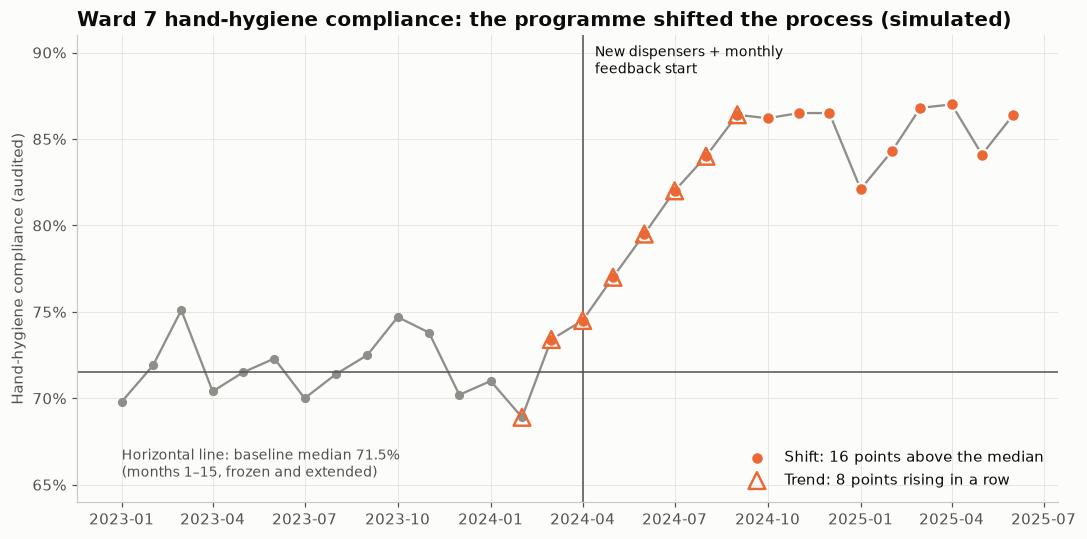

In [3]:
fig, ax = plt.subplots(figsize=(10, 5))
x, y = df["month"], df["compliance"]
ax.plot(x, y, color="#8f8e88", linewidth=1.5, marker="o", markersize=5, zorder=2)
ax.axhline(signals["median"], color="#52514e", linewidth=1)
ax.text(x.iloc[0], 65.2, f"Horizontal line: baseline median {signals['median']:.1f}%\n(months 1–15, frozen and extended)",
        fontsize=9, color="#52514e", va="bottom")
shift, trend = signals["shift"], signals["trend"]
ax.scatter(x.iloc[shift], y.iloc[shift], s=70, color=PALETTE[1], edgecolor="#fcfcfb", linewidth=1.5,
           zorder=4, label=f"Shift: {len(shift)} points above the median")
ax.scatter(x.iloc[trend], y.iloc[trend], s=120, marker="^", facecolor="none", edgecolor=PALETTE[1],
           linewidth=1.6, zorder=5, label=f"Trend: {len(trend)} points rising in a row")
ax.axvline(x.iloc[change], color="#52514e", linewidth=1)
ax.annotate("New dispensers + monthly\nfeedback start", (x.iloc[change], 90.5), xytext=(8, 0),
            textcoords="offset points", fontsize=9, va="top")
ax.set_ylim(64, 91)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0f}%"))
ax.set_ylabel("Hand-hygiene compliance (audited)")
ax.set_title("Ward 7 hand-hygiene compliance: the programme shifted the process (simulated)")
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

## How to read it

Before the programme the points scatter around the baseline median of 71.5% with no signal. Around the change, eight points in a row climb steadily (a trend, triangles), and from the last baseline month onward every point sits above the old median (a shift of 16 points, orange). Both rules flag a real improvement, not chance.

## Reference

This method comes from the research literature:

- Perla, R. J., Provost, L. P. & Murray, S. K. (2011). The run chart: a simple analytical tool for learning from variation in healthcare processes. BMJ Quality & Safety 20(1), 46–51. <https://doi.org/10.1136/bmjqs.2009.037895>

---
Standalone script: [`spc_run_chart.py`](spc_run_chart.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)